Data shape: (300, 2)
    x_km   y_km
0  1.893  8.006
1  2.370  7.114
2  2.809  1.858
3  1.028  8.129
4  8.939  2.457


/home/remandey/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


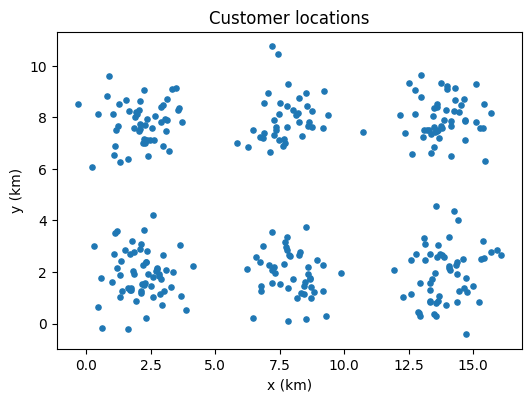

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("ic272_lab9_customers.csv")
X = df[["x_km", "y_km"]].to_numpy(dtype=float)

print("Data shape:", X.shape)
print(df.head())

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(X[:, 0], X[:, 1], s=14)
ax.set_xlabel("x (km)")
ax.set_ylabel("y (km)")
ax.set_aspect("equal")
ax.set_title("Customer locations")
plt.show()

In [2]:
def random_init(X, K, seed):
    """Choose K distinct data points as the initial centroids."""
    idx = np.random.default_rng(seed).choice(len(X), K, replace=False)
    return X[idx].copy()


def pairwise_distances(A, B):
    """Return a matrix whose (i, j) entry is the Euclidean distance A[i] to B[j]."""
    differences = A[:, np.newaxis, :] - B[np.newaxis, :, :]
    return np.sqrt(np.sum(differences ** 2, axis=2))

In [ ]:
def assign_clusters(X, centroids):
    """Return the index of the nearest centroid for each data point."""
    distances = pairwise_distances(X, centroids)
    return np.argmin(distances, axis=1)


def update_centroids(X, labels, centroids):
    """Return updated centroids; keep an old centroid if its cluster is empty."""
    new_centroids = centroids.copy()

    for k in range(len(centroids)):
        points_in_cluster = X[labels == k]

        if len(points_in_cluster) > 0:
            new_centroids[k] = np.mean(points_in_cluster, axis=0)

    return new_centroids


def distortion(X, labels, centroids):
    """Return the total squared distance to the assigned centroids."""
    differences = X - centroids[labels]
    return np.sum(differences ** 2)


def kmeans(X, init_centroids, max_iter=100):
    """Run K-means and return (centroids, labels, distortion, iterations)."""
    centroids = init_centroids.copy()

    for iteration in range(1, max_iter + 1):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, centroids)

        if np.allclose(new_centroids, centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    labels = assign_clusters(X, centroids)
    J = distortion(X, labels, centroids)

    return centroids, labels, J, iteration

In [18]:

X_check = np.array([
    [0.0, 0.0], [0.2, 0.1], [0.1, 0.3],
    [5.0, 5.0], [5.2, 5.1], [4.9, 5.2],
    [10.0, 0.0], [10.2, 0.1], [9.9, 0.2]
])

initial_check = X_check[[0, 3, 6]].copy()
centres_check, labels_check, J_check, iters_check = kmeans(
    X_check, initial_check
)

print("Final centroids:\n", centres_check)
print("Distortion:", J_check)
print("Iterations:", iters_check)

Final centroids:
 [[ 0.1         0.13333333]
 [ 5.03333333  5.1       ]
 [10.03333333  0.1       ]]
Distortion: 0.19999999999999968
Iterations: 2


In [16]:

K = 6
runs = []

for seed in range(10):
    initial_centroids = random_init(X, K, seed)
    centres, labels, J, iterations = kmeans(X, initial_centroids)

    runs.append({
        "seed": seed,
        "centroids": centres,
        "labels": labels,
        "J": J,
        "iterations": iterations
    })

    print(f"Seed {seed}: J = {J:.3f}, iterations = {iterations}")

best_run = min(runs, key=lambda result: result["J"])
worst_run = max(runs, key=lambda result: result["J"])

print("\nBest seed:", best_run["seed"], "Best J:", best_run["J"])
print("Worst seed:", worst_run["seed"], "Worst J:", worst_run["J"])

Seed 0: J = 476.247, iterations = 12
Seed 1: J = 476.247, iterations = 5
Seed 2: J = 476.247, iterations = 4
Seed 3: J = 1404.594, iterations = 4
Seed 4: J = 1404.940, iterations = 6
Seed 5: J = 476.247, iterations = 6
Seed 6: J = 476.247, iterations = 5
Seed 7: J = 1384.116, iterations = 8
Seed 8: J = 476.247, iterations = 5
Seed 9: J = 476.247, iterations = 11

Best seed: 0 Best J: 476.24680913904047
Worst seed: 4 Worst J: 1404.939583446746


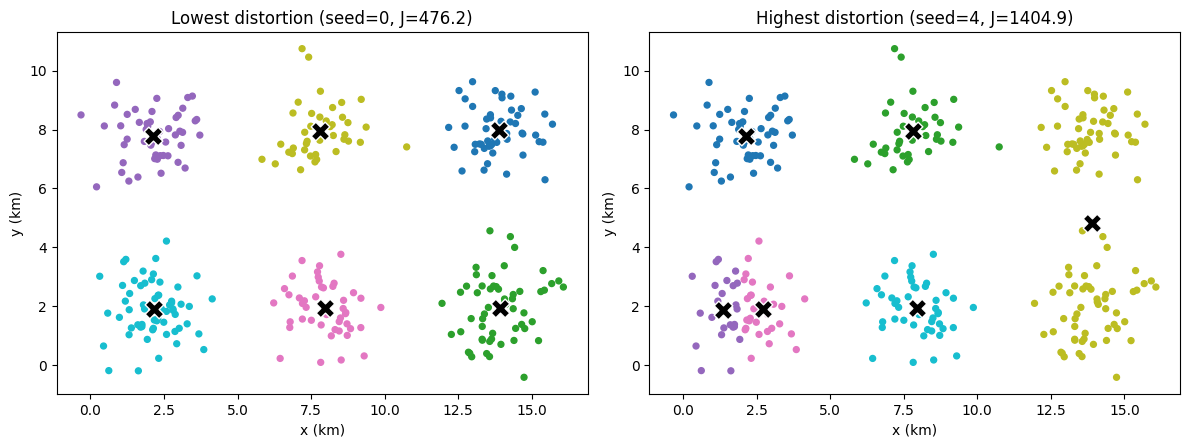

In [17]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, result, title in [
    (axes[0], best_run, "Lowest distortion"),
    (axes[1], worst_run, "Highest distortion")
]:
    ax.scatter(
        X[:, 0], X[:, 1],
        c=result["labels"], cmap="tab10", s=18
    )
    ax.scatter(
        result["centroids"][:, 0],
        result["centroids"][:, 1],
        marker="X", s=180, c="black", edgecolors="white"
    )
    ax.set_title(f"{title} (seed={result['seed']}, J={result['J']:.1f})")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

In [8]:
def best_of_kmeans(X, K, n_init=10):
    """Return the lowest-distortion K-means result from n_init random starts."""
    best_result = None

    for seed in range(n_init):
        initial_centroids = random_init(X, K, seed)
        result = kmeans(X, initial_centroids)

        if best_result is None or result[2] < best_result[2]:
            best_result = result

    return best_result

In [9]:
# Calculate the best distortion for K = 1, 2, ..., 10.
K_values = range(1, 11)
best_distortions = []

for K in K_values:
    centres, labels, J, iterations = best_of_kmeans(X, K, n_init=10)
    best_distortions.append(J)
    print(f"K = {K:2d}: best J = {J:.3f}, iterations = {iterations}")

K =  1: best J = 10571.305, iterations = 2
K =  2: best J = 4682.160, iterations = 7
K =  3: best J = 2992.871, iterations = 4
K =  4: best J = 2003.297, iterations = 9
K =  5: best J = 1156.350, iterations = 4
K =  6: best J = 476.247, iterations = 12
K =  7: best J = 428.589, iterations = 8
K =  8: best J = 395.985, iterations = 9
K =  9: best J = 367.688, iterations = 9
K = 10: best J = 345.284, iterations = 10


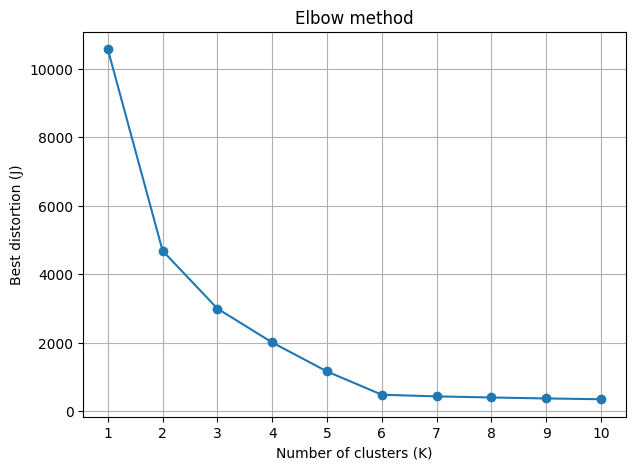

In [10]:
plt.figure(figsize=(7, 5))
plt.plot(list(K_values), best_distortions, marker="o")
plt.xticks(list(K_values))
plt.xlabel("Number of clusters (K)")
plt.ylabel("Best distortion (J)")
plt.title("Elbow method")
plt.grid(True)
plt.show()

### Task 3(c): interpreting the elbow

The elbow is the point where the distortion curve changes from a steep decrease to a much slower decrease. Before the elbow, adding a cluster substantially improves compactness; after it, each additional cluster gives only a relatively small improvement. Choose the K near this bend, rather than the K with the smallest distortion.

The exact elbow value should be read from the plot generated using your customer CSV; it is not specified by the handout.

# Homework (not vivaed today)

The following sections implement the homework tasks where the required data is available. H3 needs the Lab 8 loan CSV and its exact column names, which are not provided in this Lab 9 PDF.

## H1 — K-means++ initialisation

In [11]:
def kmeans_pp_init(X, K, seed):
    """Choose K initial centroids using the K-means++ procedure."""
    rng = np.random.default_rng(seed)

    # Choose the first centroid uniformly.
    first_index = rng.integers(len(X))
    chosen_indices = [first_index]
    centroids = [X[first_index].copy()]

    while len(centroids) < K:
        # Squared distance to the nearest centroid already chosen.
        distances = pairwise_distances(X, np.array(centroids))
        min_squared_distances = np.min(distances ** 2, axis=1)

        # Do not select an already selected data point again.
        min_squared_distances[chosen_indices] = 0.0
        total = np.sum(min_squared_distances)

        if total == 0:
            # All remaining points have zero distance (e.g. duplicate data).
            remaining = np.setdiff1d(np.arange(len(X)), chosen_indices)
            next_index = rng.choice(remaining)
        else:
            probabilities = min_squared_distances / total
            next_index = rng.choice(len(X), p=probabilities)

        chosen_indices.append(int(next_index))
        centroids.append(X[next_index].copy())

    return np.array(centroids)

In [12]:
# Compare 100 random starts and 100 K-means++ starts for K=6.
K = 6
random_J = []
plusplus_J = []

for seed in range(100):
    random_centres = random_init(X, K, seed)
    _, _, J_random, _ = kmeans(X, random_centres)
    random_J.append(J_random)

    pp_centres = kmeans_pp_init(X, K, seed)
    _, _, J_pp, _ = kmeans(X, pp_centres)
    plusplus_J.append(J_pp)

best_overall = min(min(random_J), min(plusplus_J))
threshold = 1.05 * best_overall

random_bad = sum(J > threshold for J in random_J)
plusplus_bad = sum(J > threshold for J in plusplus_J)

print("Best distortion across both methods:", best_overall)
print(f"Random initialisation: {random_bad}/100 runs are more than 5% above best")
print(f"K-means++:             {plusplus_bad}/100 runs are more than 5% above best")

Best distortion across both methods: 476.24680913904047
Random initialisation: 38/100 runs are more than 5% above best
K-means++:             22/100 runs are more than 5% above best


**Interpretation:** Compare the two counts. If the K-means++ count is lower, it reduced the frequency of poor local minima in these trials. It does not guarantee the global optimum, so it does not necessarily remove the problem.

## H2 — Outliers

Distortion: 1410.4125874841923
Cluster sizes: [103  46  55   3  51  45]


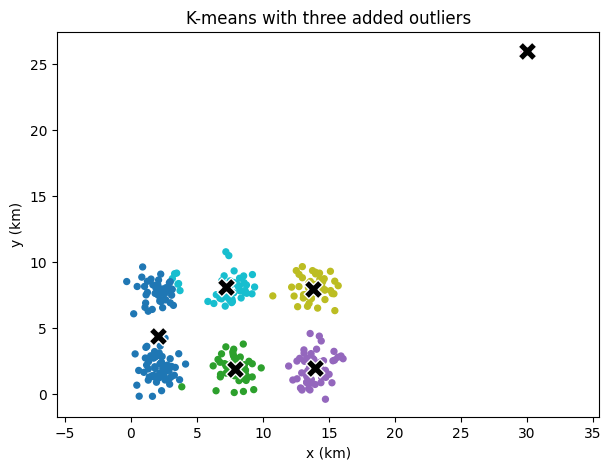

In [13]:
# Add three outliers near (30, 26), then rerun K-means.
outliers = np.array([
    [30.0, 26.0],
    [30.2, 26.1],
    [29.8, 25.9]
])

X_with_outliers = np.vstack([X, outliers])
centres_out, labels_out, J_out, iterations_out = best_of_kmeans(
    X_with_outliers, K=6, n_init=10
)

cluster_sizes = np.bincount(labels_out, minlength=6)
print("Distortion:", J_out)
print("Cluster sizes:", cluster_sizes)

plt.figure(figsize=(7, 5))
plt.scatter(
    X_with_outliers[:, 0], X_with_outliers[:, 1],
    c=labels_out, cmap="tab10", s=18
)
plt.scatter(
    centres_out[:, 0], centres_out[:, 1],
    marker="X", s=180, c="black", edgecolors="white"
)
plt.xlabel("x (km)")
plt.ylabel("y (km)")
plt.title("K-means with three added outliers")
plt.axis("equal")
plt.show()

**Interpretation:** Inspect the centroid near `(30, 26)` and the cluster sizes. A centroid may be allocated to the three outliers, leaving only five centroids for the original neighbourhoods. Two real neighbourhoods may then be merged. This illustrates why squared-distance K-means is sensitive to outliers: distant points can have a large influence on the objective and centroid means.

## H3 — Scale, again (requires the Lab 8 loan data)

The Lab 9 handout says to use only **income** and **utilisation** for clustering, and to use the default label only afterwards to describe the clusters. The Lab 8 data filename and exact column names are not specified here. Set them in the next cell to match your Lab 8 CSV.

In [14]:
# EDIT these values to match your Lab 8 loan CSV.
LOAN_CSV = "YOUR_LAB8_LOAN_DATA.csv"
INCOME_COLUMN = "income"
UTILISATION_COLUMN = "utilisation"
DEFAULT_COLUMN = "default"  # label used only for reporting cluster default rates

# Load and select the two clustering features.
loan_df = pd.read_csv(LOAN_CSV)
loan_features = loan_df[[INCOME_COLUMN, UTILISATION_COLUMN]].to_numpy(dtype=float)
default_labels = loan_df[DEFAULT_COLUMN].to_numpy(dtype=float)

# Standardise each feature using its mean and standard deviation.
feature_means = np.mean(loan_features, axis=0)
feature_stds = np.std(loan_features, axis=0)
feature_stds[feature_stds == 0] = 1.0
loan_standardised = (loan_features - feature_means) / feature_stds

# Cluster raw features and standardised features separately.
raw_centres, raw_cluster_labels, raw_J, _ = best_of_kmeans(
    loan_features, K=2, n_init=10
)
std_centres, std_cluster_labels, std_J, _ = best_of_kmeans(
    loan_standardised, K=2, n_init=10
)

def describe_loan_clusters(cluster_labels, features, defaults):
    """Report cluster size, mean features, and default rate."""
    rows = []

    for cluster_id in range(2):
        mask = cluster_labels == cluster_id
        rows.append({
            "cluster": cluster_id,
            "size": int(np.sum(mask)),
            "mean_income": float(np.mean(features[mask, 0])),
            "mean_utilisation": float(np.mean(features[mask, 1])),
            "default_rate": float(np.mean(defaults[mask]))
        })

    return pd.DataFrame(rows)

print("Raw-feature clustering (J =", raw_J, ")")
display(describe_loan_clusters(raw_cluster_labels, loan_features, default_labels))

print("Standardised-feature clustering (J =", std_J, ")")
display(describe_loan_clusters(std_cluster_labels, loan_features, default_labels))

FileNotFoundError: [Errno 2] No such file or directory: 'YOUR_LAB8_LOAN_DATA.csv'

**Interpretation:** On raw columns, a feature with a much larger numerical scale can dominate Euclidean distance and largely decide the split. Standardisation puts the two features on comparable scales. Compare the reported default rates to see which clustering produced groups with more distinct risk profiles. The default label is not used in either clustering run.

## H4 — Image segmentation

In [ ]:
# Load the image and keep the RGB channels, as specified in the handout.
img = plt.imread("ic272_lab9 image.png")
img = img[:, :, :3]

# Convert pixels into an (number_of_pixels, 3) array.
height, width, channels = img.shape
pixels = img.reshape(-1, 3).astype(float)

print("Image shape:", img.shape)
print("Pixel data shape:", pixels.shape)

In [ ]:
# Segment the image for K=2, 3, and 4.
# One initialisation per K keeps this exercise simple and reasonably fast.
segmented_images = {}

for K in [2, 3, 4]:
    initial_centres = random_init(pixels, K, seed=K)
    centres, pixel_labels, J, iterations = kmeans(
        pixels, initial_centres, max_iter=100
    )

    # Replace each pixel by the RGB colour of its assigned centroid.
    segmented_pixels = centres[pixel_labels]
    segmented_images[K] = segmented_pixels.reshape(height, width, 3)

    print(f"K={K}: distortion={J:.3f}, iterations={iterations}")

In [ ]:
# Display the original image and the three segmented versions.
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(img)
axes[0].set_title("Original")

for ax, K in zip(axes[1:], [2, 3, 4]):
    ax.imshow(np.clip(segmented_images[K], 0, 1))
    ax.set_title(f"K = {K}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### H4: interpretation

Compare the three segmented images and identify the value of K at which the four visual regions become distinguishable. The elbow can suggest a smaller K because it measures reduction in total squared colour error, not whether every semantically meaningful region receives its own cluster. Two visually distinct regions with similar RGB colours may be merged by colour-only K-means.

## Final checklist

- [ ] Task 1 functions are implemented with the required names.
- [ ] Check Task 1 against the A1–A15 points from the lecture slides.
- [ ] Task 2 prints all ten distortions and iteration counts, and plots best/worst runs.
- [ ] Task 3 plots distortion against K and records the elbow chosen from your plot.
- [ ] Homework H1–H4 are run when their required datasets are available.

**Important:** K-means is sensitive to initialisation and outliers. The exact numerical outputs depend on the supplied customer CSV, lecture example points, image, and loan dataset.